In [1]:
import oqupy
import matplotlib.pyplot as plt

In [2]:
sigma_x = oqupy.operators.sigma("x")
sigma_y = oqupy.operators.sigma("y")
sigma_z = oqupy.operators.sigma("z")
up_density_matrix = oqupy.operators.spin_dm("z+")
down_density_matrix = oqupy.operators.spin_dm("z-")

--> TEMPO computation:
100.0%  500 of  500 [########################################] 00:44:01
Elapsed time: 2641.9s


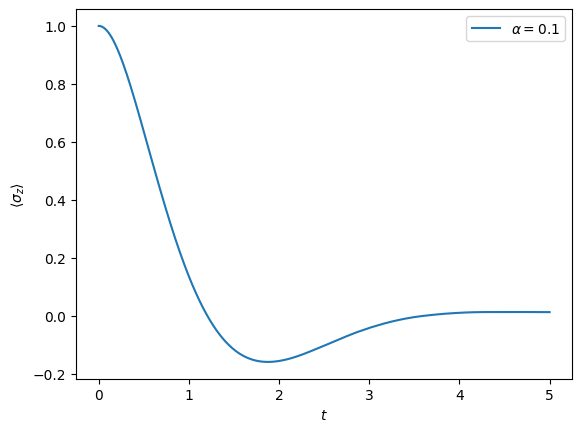

In [3]:
omega_0 = 0.
Omega = 1.
omega_cutoff = 5.
alpha = 0.1
temperature = 0
start_time = 0.
end_time = 5.

system = oqupy.System(omega_0 * sigma_z + Omega * sigma_x)

j_function = lambda omega: 2 * omega * alpha

correlations = oqupy.CustomSD(j_function=j_function,
                              cutoff=omega_cutoff,
                              cutoff_type='exponential',
                              temperature=temperature)
bath = oqupy.Bath(sigma_z, correlations)

tempo_parameters = oqupy.TempoParameters(dt=0.01, tcut=5., epsrel=1e-8)

tempo = oqupy.Tempo(system=system,
                    bath=bath,
                    parameters=tempo_parameters,
                    initial_state=up_density_matrix,
                    start_time=start_time)

tempo.compute(end_time=end_time)

dynamics = tempo.get_dynamics()
t_list, sigma_z_list = dynamics.expectations(sigma_z, real=True)
plt.plot(t_list, sigma_z_list, label=fr'$\alpha={alpha:.1f}$')
plt.xlabel(r'$t$')
plt.ylabel(r'$\langle\sigma_z\rangle$')
plt.legend()